# Categorical data and model-based methods

mice-py 0.3 adds nine of R mice's model-based methods to the five donor methods of
`02_imputation_methods.ipynb`: `norm`, `norm.boot`, `norm.nob`, `norm.predict` and `mean` impute
new numbers in a numeric column; `logreg`, `logreg.boot`, `polyreg` and `polr` impute the labels of
a categorical column. As in R, the default method of a column now depends on its type.

The other notebooks use the numeric `nhanes` data; this one also uses R's `boys` data, which has
numeric, ordered categorical and text columns.

1. Imports and data
2. The default method follows the column type
3. Imputing with the defaults
4. Choosing methods yourself
5. Model-based methods for numeric columns
6. Method parameters
7. Checks before the chains start
8. Fit and pool

## 1. Imports and data

`boys` holds measurements of 748 Dutch boys, a random sample from the data behind the Dutch growth
references of 1997: age (years), height (`hgt`), weight (`wgt`), body mass index (`bmi`), head
circumference (`hc`), genital development (`gen`, stages G1 to G5), pubic hair (`phb`, stages P1
to P6), testicular volume (`tv`, ml) and region (`reg`: north, east, west, south, city).

A CSV file carries no types: `gen`, `phb` and `reg` arrive as text (`object`). `gen` and `phb` are
stages in a fixed order, so they are declared as ordered categoricals; `reg` stays text, which
mice-py treats as an unordered categorical.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import imputation
from imputation import MICE
from plotting import bwplot

plt.rcParams["figure.dpi"] = 72  # keeps the stored image small

nhanes = pd.read_csv("data/nhanes.csv")
boys_csv = pd.read_csv("data/boys.csv")
boys = boys_csv.assign(
    gen=pd.Categorical(boys_csv["gen"], categories=["G1", "G2", "G3", "G4", "G5"], ordered=True),
    phb=pd.Categorical(boys_csv["phb"], categories=["P1", "P2", "P3", "P4", "P5", "P6"], ordered=True),
)
pd.DataFrame({"as read": boys_csv.dtypes, "declared": boys.dtypes, "missing": boys.isna().sum()})

,as read,declared,missing
age,float64,float64,0
hgt,float64,float64,20
wgt,float64,float64,4
bmi,float64,float64,21
hc,float64,float64,46
gen,object,category,503
phb,object,category,503
tv,float64,float64,522
reg,object,object,3


## 2. The default method follows the column type

The default method of an incomplete column depends on its type, as R's
`defaultMethod = c("pmm", "logreg", "polyreg", "polr")` sets it:

| Incomplete column | Default method |
|---|---|
| numeric | `pmm` |
| boolean, or two categories | `logreg` |
| unordered categorical or text, more than two categories | `polyreg` |
| ordered categorical, more than two categories | `polr` |

The categories of a `category` column are its declared ones, unused ones included; those of a text
column are its distinct observed values. A complete column gets `""`. In 0.2 every incomplete column
got `pmm`.

`imputation.make_method` (R's `make.method`) shows the method of each column. In `nhanes` every
column is numeric; with `hyp` as text (`"no"`, `"yes"`) or as booleans, `hyp` has two categories
and gets `logreg`:

In [2]:
nhanes_text = nhanes.assign(hyp=nhanes["hyp"].map({1: "no", 2: "yes"}))
nhanes_bool = nhanes.assign(hyp=nhanes["hyp"].map({1: False, 2: True}).astype("boolean"))
print(imputation.make_method(nhanes))
print(imputation.make_method(nhanes_text))
print(imputation.make_method(nhanes_bool))

{'age': '', 'bmi': 'pmm', 'hyp': 'pmm', 'chl': 'pmm'}
{'age': '', 'bmi': 'pmm', 'hyp': 'logreg', 'chl': 'pmm'}
{'age': '', 'bmi': 'pmm', 'hyp': 'logreg', 'chl': 'pmm'}


In `boys` as read from the CSV file, `gen`, `phb` and `reg` are text with more than two values and
get `polyreg`; declared as ordered, `gen` and `phb` get `polr`:

In [3]:
print(imputation.make_method(boys_csv))
print(imputation.make_method(boys))

{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'polyreg', 'phb': 'polyreg', 'tv': 'pmm', 'reg': 'polyreg'}
{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'polr', 'phb': 'polr', 'tv': 'pmm', 'reg': 'polyreg'}


## 3. Imputing with the defaults

`impute` without `method` gives each column its default. The completed datasets keep the dtypes of
the data; for `gen` and `phb` that includes the declared categories and their order:

In [4]:
mice = MICE(boys)
mice.impute(seed=1)
print(mice.method)

completed = mice.imputed_datasets[0]
print(repr(completed["gen"].dtype))
print("all dtypes as in boys:", (completed.dtypes == boys.dtypes).all())
print("missing values left:", completed.isna().sum().sum())

{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'polr', 'phb': 'polr', 'tv': 'pmm', 'reg': 'polyreg'}
CategoricalDtype(categories=['G1', 'G2', 'G3', 'G4', 'G5'], ordered=True, categories_dtype=object)
all dtypes as in boys: True
missing values left: 0


`gen` is missing for 503 of the 748 boys. The share of each stage among the observed values and
among the imputed ones (the five completed datasets together):

In [5]:
missing_gen = boys["gen"].isna()
imputed = pd.concat([data.loc[missing_gen] for data in mice.imputed_datasets])
pd.DataFrame(
    {
        "observed": boys["gen"].value_counts(normalize=True, sort=False),
        "imputed": imputed["gen"].value_counts(normalize=True, sort=False),
    }
).round(3)

,observed,imputed
gen,,
G1,0.229,0.499
G2,0.204,0.190
G3,0.090,0.058
G4,0.171,0.093
G5,0.306,0.161


Half of the imputed values are G1, against a fifth of the observed ones. The missing values are
not spread evenly over the ages; counts of `gen` by age group (years):

In [6]:
def age_group(age):
    return pd.cut(age, bins=[0, 5, 10, 15, 22], right=False, labels=["0-5", "5-10", "10-15", "15-21"])


pd.crosstab(age_group(boys["age"]), boys["gen"].cat.add_categories("missing").fillna("missing"))

gen,G1,G2,G3,G4,G5,missing
age,,,,,,
0-5,0,0,0,0,0,291
5-10,22,7,0,0,0,39
10-15,34,41,17,19,9,67
15-21,0,2,5,23,66,106


`gen` is missing for every boy under 5, and the boys under 10 with an observed `gen` are mostly at
G1. `polr` imputes `gen` from age and the other columns. The imputed stages by age group (shares
per row, the five datasets together) depend on age as the observed ones do, mostly G1 for the
young boys and mostly G5 for the oldest, and the many young boys among the missing make G1
frequent:

In [7]:
pd.crosstab(age_group(imputed["age"]), imputed["gen"], normalize="index").round(2)

gen,G1,G2,G3,G4,G5
age,,,,,
0-5,0.72,0.23,0.03,0.01,0.00
5-10,0.65,0.26,0.05,0.04,0.01
10-15,0.21,0.22,0.15,0.25,0.17
15-21,0.02,0.04,0.07,0.23,0.65


## 4. Choosing methods yourself

A `method` dict sets the method of the columns it lists; a column left out gets the default of its
type (in 0.2 it got `pmm`). Here `gen` gets `polyreg`, and `phb` keeps `polr`:

In [8]:
mice_dict = MICE(boys)
mice_dict.impute(method={"gen": "polyreg"}, seed=1)
print(mice_dict.method)

{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'polyreg', 'phb': 'polr', 'tv': 'pmm', 'reg': 'polyreg'}


`default_method` replaces the four defaults, in the order of the table in section 2; below, `cart`
for the categorical columns with more than two categories. The methods of 0.2, `pmm` for every
column, are `method="pmm"`, or `default_method=("pmm",) * 4`, which also covers the columns a
method dict leaves out. With the same seed the two give the same datasets:

In [9]:
mice_cart = MICE(boys)
mice_cart.impute(default_method=("pmm", "logreg", "cart", "cart"), seed=1)
print(mice_cart.method)

mice_pmm = MICE(boys)
mice_pmm.impute(method="pmm", seed=1)
mice_pmm_default = MICE(boys)
mice_pmm_default.impute(default_method=("pmm",) * 4, seed=1)
print(mice_pmm.method)
same = all(a.equals(b) for a, b in zip(mice_pmm.imputed_datasets, mice_pmm_default.imputed_datasets))
print("same datasets:", same)

{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'cart', 'phb': 'cart', 'tv': 'pmm', 'reg': 'cart'}
{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'pmm', 'phb': 'pmm', 'tv': 'pmm', 'reg': 'pmm'}
same datasets: True


## 5. Model-based methods for numeric columns

The donor methods impute values observed in the same column; `norm`, `norm.boot`, `norm.nob`,
`norm.predict` and `mean` impute new numbers. `tv`, observed between 1 and 25, is missing for 522
boys. Below it is imputed with each method in turn, with the same seed; the other columns keep
their defaults. The box plots show the observed values (blue) and the imputed values of each
completed dataset (red) under `pmm` and under `norm`; the two panels have their own y-axis.

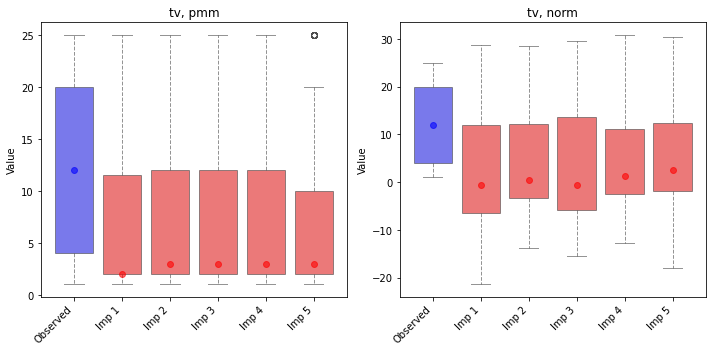

In [10]:
missing_tv = boys["tv"].isna()
runs = {}
for name in ["pmm", "norm", "norm.boot", "norm.nob", "norm.predict", "mean"]:
    runs[name] = MICE(boys)
    runs[name].impute(method={"tv": name}, seed=1)

tv_both = [
    pd.DataFrame({"tv, pmm": pmm_data["tv"], "tv, norm": norm_data["tv"]})
    for pmm_data, norm_data in zip(runs["pmm"].imputed_datasets, runs["norm"].imputed_datasets)
]
tv_observed = pd.DataFrame({"tv, pmm": ~missing_tv, "tv, norm": ~missing_tv}).astype(int)
bwplot(tv_both, tv_observed);

`pmm` imputes observed volumes. `norm` draws from a normal linear regression: its imputations go
beyond the observed range, and many are negative, a volume no boy has. For each method: the
smallest and the largest imputed value, their standard deviation (`sd`), the share below 0, the
standard deviation of a cell's imputations across the five datasets, averaged over the cells
(`sd between`), and whether every cell has the same imputation in all datasets (`same in all`):

In [11]:
rows = {}
for name, run in runs.items():
    tv_imputed = pd.concat([data.loc[missing_tv, "tv"] for data in run.imputed_datasets], axis=1)
    values = tv_imputed.to_numpy()
    rows[name] = {
        "min": values.min(),
        "max": values.max(),
        "sd": values.std(ddof=1),
        "below 0": (values < 0).mean(),
        "sd between": tv_imputed.std(axis=1).mean(),
        "same in all": tv_imputed.nunique(axis=1).eq(1).all(),
    }
pd.DataFrame.from_dict(rows, orient="index").round(2)

,min,max,sd,below 0,sd between,same in all
pmm,1.00,25.00,7.52,0.00,2.25,False
norm,-21.41,30.81,10.39,0.46,4.06,False
norm.boot,-21.31,34.21,11.08,0.49,4.43,False
norm.nob,-15.85,32.09,10.44,0.50,3.77,False
norm.predict,-10.21,23.93,9.79,0.56,1.34,False
mean,11.89,11.89,0.00,0.00,0.00,True


Under `norm`, 46% of the imputed volumes are negative; `pmm` stays between 1 and 25.

`sd between` measures how much the datasets differ in a cell; this variation between the datasets
is what enters the pooled standard errors as the uncertainty about the missing values.

- `norm` and `norm.boot` are proper: they draw the parameters of the regression (from their
  posterior, or through a bootstrap sample) and add a random residual.
- `norm.nob` adds the residual but takes the estimated parameters as known. The documentation warns
  that it understates the variability in small samples; with 226 observed values its `sd between`
  is only somewhat below that of `norm` here.
- `mean` imputes the observed mean, 11.89, in every cell of every dataset.
- `norm.predict` imputes the prediction itself, the same in every dataset given the predictors; it
  varies here only because its predictors, among them `gen` and `phb`, are imputed too. Over half
  of its imputations are below 0: the linear model predicts a negative volume for many of these
  boys.

`norm.nob`, `norm.predict` and `mean` are improper: they ignore the uncertainty of the model
(`norm.predict` and `mean` also the residual noise), so the standard errors after pooling are too
small. Use them for comparisons, not for analyses.

## 6. Method parameters

A parameter of a method is passed to `impute` as the method name with its dots replaced by
underscores, then the parameter: `norm_boot_ridge` is `ridge` of `norm.boot`, `polyreg_maxit` is
`maxit` of `polyreg` (R's `nnet.maxit`), `polr_log_fallback` is `log_fallback` of `polr` (R's
`polr.to.loggedEvents`). `reg` gets `polyreg` by default, so `polyreg_maxit` applies to it:

In [12]:
mice_params = MICE(boys)
mice_params.impute(method={"tv": "norm.boot"}, norm_boot_ridge=1e-4, polyreg_maxit=200, seed=1)
print(mice_params.method)

{'age': '', 'hgt': 'pmm', 'wgt': 'pmm', 'bmi': 'pmm', 'hc': 'pmm', 'gen': 'polr', 'phb': 'polr', 'tv': 'norm.boot', 'reg': 'polyreg'}


R's `MASS::polr` needs at least three categories. On a target with two, `polr` fits the
multinomial model of `polyreg` instead, as R does, and with `polr_log_fallback=True` each fallback
becomes a row of `logged_events`. `hyp` of `nhanes_text` has two categories; with 2 imputations
and 2 iterations, `polr` runs four times and falls back each time. Logged events also issue a
`UserWarning`, caught here to print its text:

In [13]:
mice_polr = MICE(nhanes_text)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    mice_polr.impute(n_imputations=2, maxit=2, method={"hyp": "polr"}, polr_log_fallback=True, seed=1)
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")
mice_polr.logged_events

,it,im,dep,meth,out
0,1,1,hyp,polr,polr falls back to multinom
1,1,2,hyp,polr,polr falls back to multinom
2,2,1,hyp,polr,polr falls back to multinom
3,2,2,hyp,polr,polr falls back to multinom


## 7. Checks before the chains start

`impute` checks each method against the type of its column before the chains start and raises
`ValueError` naming the column. The loop below catches the errors to print them:

- a text column with more than 50 distinct values gets `polyreg` by default, and `polyreg` models
  at most 50 categories, as in R. Here a copy of `boys` gets an identifier `id` that is missing in
  every tenth row;
- `logreg` imputes two categories; `reg` has five;
- the `norm` methods and `mean` impute numbers; `gen` is categorical.

In [14]:
boys_id = boys.assign(id=[f"B{i:03d}" for i in range(1, len(boys) + 1)])
boys_id.loc[boys_id.index % 10 == 0, "id"] = None

for data, method in [(boys_id, None), (boys, {"reg": "logreg"}), (boys, {"gen": "norm"})]:
    try:
        MICE(data).impute(method=method, seed=1)
    except ValueError as error:
        print(f"{error}\n")

Column 'id' has 673 distinct observed values, more categories than polyreg can model: R's mice allows at most 50 ('Maximum number of categories (50) exceeded'). Text columns of names or identifiers often look like this, and the default method of a text column with more than two values is polyreg. Impute the column with a donor method instead, for example method={'id': 'pmm'}, or remove it from the data if it identifies the rows.

Column 'reg': logreg imputes a target with two categories, but the column has 5 distinct observed values ('city', 'east', 'north', 'south', 'west'). Use polyreg for more than two categories, or a donor method (pmm, cart, rf, sample).

Column 'gen' is ordered categorical (dtype category), but norm imputes numeric columns only (R's mice.impute.norm imputes NA here). Methods for this column: polr, polyreg, or a donor method (pmm, cart, rf, sample).



The remedies:

- `id`: an identifier carries no information for the imputation, so drop it
  (`boys_id.drop(columns="id")`). The donor method that the message names is for a text column
  with some dozens of values that is to be imputed. With `method={"id": "pmm"}` here, `id` would
  stay a predictor with one dummy column per value, and `polyreg` of `reg` stops with too many
  weights.
- `reg`: `polyreg`, its default, or a donor method.
- `gen`: `polr`, its default, `polyreg` or a donor method.

A categorical method on a numeric column is allowed, with R's warning (caught here to print its
text). `polyreg` then treats each observed volume of `tv` as a category and imputes these values.
If the numbers are codes of categories, make the column categorical; otherwise use a method for
numeric columns.

In [15]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    MICE(boys).impute(method={"tv": "polyreg"}, seed=1)
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")

Imputation method polyreg is for categorical data.


## 8. Fit and pool

As in `04_analysis_workflow.ipynb`: fit a model to each completed dataset of section 3 and pool
the fits with Rubin's rules. patsy codes `gen` with one dummy per stage after G1.

In [16]:
mice.fit("tv ~ age + gen")
table = mice.pool()["table"]
table[["estimate", "std_error", "df", "p_value", "conf_low", "conf_high", "fmi"]].round(3)

,estimate,std_error,df,p_value,conf_low,conf_high,fmi
term,,,,,,,
Intercept,1.061,0.406,7.521,0.033,0.115,2.007,0.770
gen[T.G2],0.802,0.694,6.532,0.288,-0.863,2.468,0.816
gen[T.G3],4.265,1.483,4.989,0.035,0.451,8.079,0.904
gen[T.G4],8.580,1.192,5.554,0.001,5.606,11.553,0.870
gen[T.G5],12.916,0.915,7.398,0.000,10.775,15.057,0.775
age,0.354,0.079,4.940,0.007,0.151,0.557,0.907


`tv` and `gen` are missing for about two thirds of the boys, and the fraction of missing
information is high: `fmi` lies between 0.77 and 0.91, and the degrees of freedom are small, 4.9 to
7.5.

## Summary

- The default method follows the column type, as R's `defaultMethod`: `pmm` for numeric columns,
  `logreg` for two categories, `polyreg` and `polr` for unordered and ordered categorical columns
  with more. `imputation.make_method` shows it.
- Declare the types: a CSV file gives text, which counts as unordered categorical.
- A `method` dict sets some columns, the others keep their defaults; `default_method` replaces the
  defaults; `method="pmm"` gives the methods of 0.2.
- `norm`, `norm.boot`, `norm.nob` and `norm.predict` impute new numbers, also outside the observed
  range; `norm.nob`, `norm.predict` and `mean` understate the uncertainty.
- Method parameters: the method name with dots as underscores, then the parameter
  (`norm_boot_ridge`, `polyreg_maxit`, `polr_log_fallback`).
- A method that cannot impute the type of its column raises `ValueError` before the chains start;
  a categorical method on a numeric column warns.

Next: the Imputation Methods page of the documentation, for every method and its parameters, and
the Upgrading page, for what changed from 0.2.